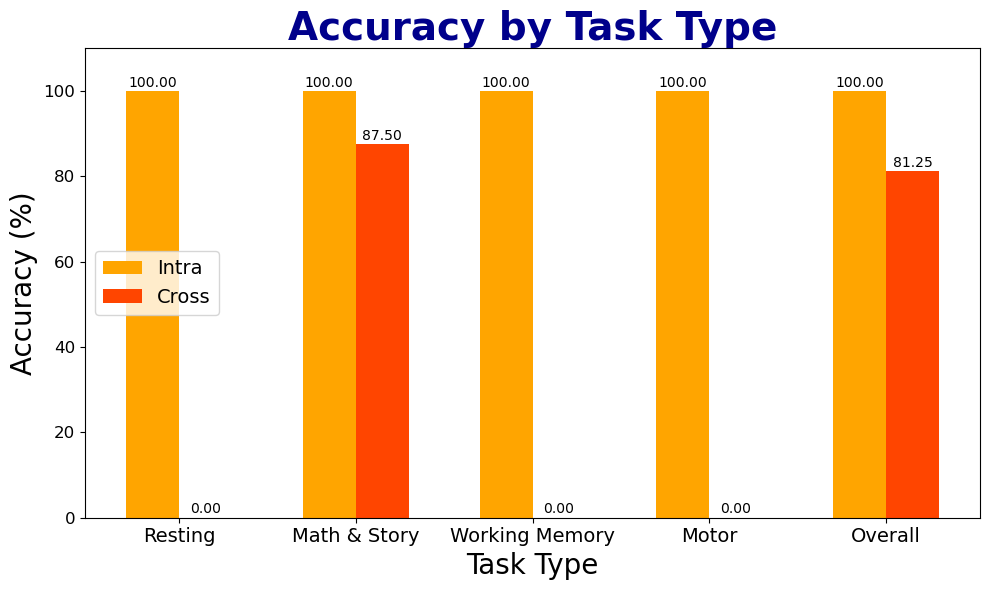

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#Correct full paths to your CSV files
intra_path = r"C:\Users\Surface\OneDrive\Documents\GitHub\advanced ML3\Deep_Learning_MEG\Output\Intra\best_model_MultiviewAttention_intra_20250601_225149.csv"
cross_path = r"C:\Users\Surface\OneDrive\Documents\GitHub\advanced ML3\Deep_Learning_MEG\Output\both\test_metrics_MultiviewAttention_both_20250601_234504.csv"

#Load the files
df_intra = pd.read_csv(intra_path)
df_cross = pd.read_csv(cross_path)

#Map patient_id % 10 to task names
task_map = {0: "Resting", 1: "Math & Story", 2: "Working Memory", 3: "Motor"}

#Intra accuracies from summary columns
intra_accuracies = {
    "Resting": df_intra["test_resting_accuracy"].mean(),
    "Math & Story": df_intra["test_math_accuracy"].mean(),
    "Working Memory": df_intra["test_memory_accuracy"].mean(),
    "Motor": df_intra["test_motor_accuracy"].mean(),
    "Overall": df_intra["test_overall_accuracy"].mean()
}

#Cross accuracies from predictions
df_cross["task"] = df_cross["patient_id"] % 10
df_cross["task"] = df_cross["task"].map(task_map)

cross_accuracies = {}
for task in task_map.values():
    task_df = df_cross[df_cross["task"] == task]
    correct = (task_df["y_true"] == task_df["y_pred"]).sum()
    accuracy = correct / len(task_df) if len(task_df) > 0 else 0
    cross_accuracies[task] = accuracy

cross_accuracies["Overall"] = (df_cross["y_true"] == df_cross["y_pred"]).mean()

#Prepare data for plotting
tasks = ["Resting", "Math & Story", "Working Memory", "Motor", "Overall"]
intra_vals = [intra_accuracies[t] * 100 for t in tasks]
cross_vals = [cross_accuracies[t] * 100 for t in tasks]

#Plotting
x = np.arange(len(tasks))
width = 0.3

plt.figure(figsize=(10, 6))
plt.bar(x - 0.5 * width, intra_vals, width, label='Intra', color='orange')
plt.bar(x + 0.5 * width, cross_vals, width, label='Cross', color='orangered')

#Add labels on bars
for i in range(len(tasks)):
    plt.text(x[i] - 0.5 * width, intra_vals[i] + 1, f"{intra_vals[i]:.2f}", ha='center', fontsize=10)
    plt.text(x[i] + 0.5 * width, cross_vals[i] + 1, f"{cross_vals[i]:.2f}", ha='center', fontsize=10)

plt.title("Accuracy by Task Type", fontsize=28, weight='bold', color='darkblue')
plt.xlabel("Task Type", fontsize=20)
plt.ylabel("Accuracy (%)", fontsize=20)
plt.xticks(x, tasks, fontsize=14)
plt.yticks(fontsize=12)
plt.ylim(0, 110)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()


In [2]:
df_cross["task"] = df_cross["patient_id"] % 10
df_cross["task"] = df_cross["task"].map({
    0: "Resting", 
    1: "Math & Story", 
    2: "Working Memory", 
    3: "Motor"
})

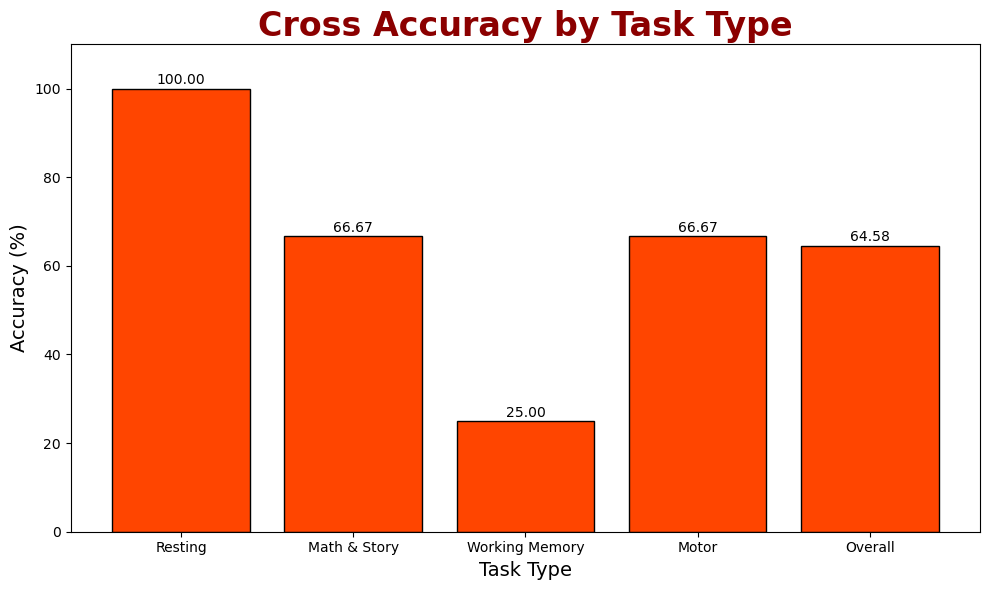

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

#Load the cross summary file
cross_path = r"C:\Users\Surface\OneDrive\Documents\GitHub\advanced ML3\Deep_Learning_MEG\Output\Cross\best_model_MultiviewAttention_cross_20250528_231723.csv"
df_cross = pd.read_csv(cross_path)

#Extract average accuracies for each task and overall
task_accuracies = {
    "Resting": df_cross["test_resting_accuracy"].mean(),
    "Math & Story": df_cross["test_math_accuracy"].mean(),
    "Working Memory": df_cross["test_memory_accuracy"].mean(),
    "Motor": df_cross["test_motor_accuracy"].mean(),
    "Overall": df_cross["test_overall_accuracy"].mean()
}

#Plotting
tasks = list(task_accuracies.keys())
accuracies = [v * 100 for v in task_accuracies.values()]  # convert to percentage

#Plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(tasks, accuracies, color='orangered', edgecolor='black')

#Add value labels above bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1, f"{height:.2f}", ha='center', fontsize=10)

#Format plot
ax.set_title("Cross Accuracy by Task Type", fontsize=24, weight='bold', color='darkred')
ax.set_ylabel("Accuracy (%)", fontsize=14)
ax.set_xlabel("Task Type", fontsize=14)
ax.set_ylim(0, 110)
plt.tight_layout()
plt.show()


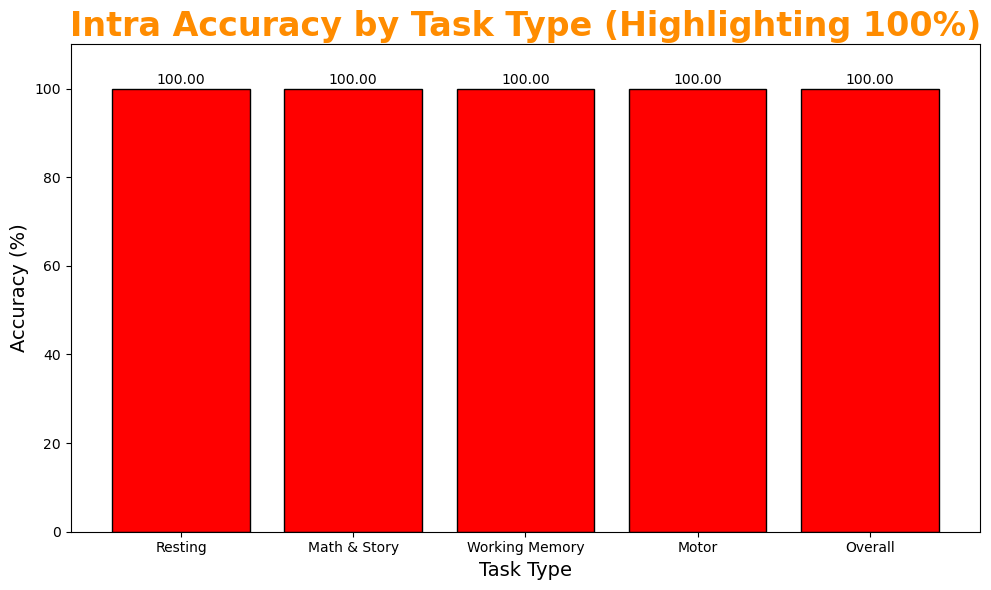

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Actual uploaded path
intra_path = intra_path = "best_model_MultiviewAttention_intra_20250601_225149.csv"
df_intra = pd.read_csv(intra_path)

# Extract accuracy per task
task_accuracies = {
    "Resting": df_intra["test_resting_accuracy"].mean(),
    "Math & Story": df_intra["test_math_accuracy"].mean(),
    "Working Memory": df_intra["test_memory_accuracy"].mean(),
    "Motor": df_intra["test_motor_accuracy"].mean(),
    "Overall": df_intra["test_overall_accuracy"].mean()
}

# Convert to percentages
tasks = list(task_accuracies.keys())
accuracies = [v * 100 for v in task_accuracies.values()]
colors = ["red" if acc == 100 else "orange" for acc in accuracies]

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(tasks, accuracies, color=colors, edgecolor='black')

# Labels on bars
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1, f"{acc:.2f}", ha='center', fontsize=10)

# Format
ax.set_title("Intra Accuracy by Task Type (Highlighting 100%)", fontsize=24, weight='bold', color='darkorange')
ax.set_ylabel("Accuracy (%)", fontsize=14)
ax.set_xlabel("Task Type", fontsize=14)
ax.set_ylim(0, 110)
plt.tight_layout()
plt.show()